# EXPERIMENT NO. 11
## A Neural Network Algorithm to Classify Data into Multiple Classes Based on Predictor Variables

### Aim
To study how an Artificial Neural Network (ANN) classifies data into multiple classes using predictor variables.

### Objectives
1. Understand the basic structure of an artificial neural network.
2. Identify predictor variables, weights, bias, and activation functions.
3. Understand multiclass prediction using an output neuron for each class.
4. Study forward propagation, loss calculation, and backpropagation learning.
5. Evaluate the model using common classification measures.

### Relevance
Multiclass classification assigns observations to one of three or more categories. Applications include flower-species identification, product categorization, document classification, and image recognition.

### Theory

An **Artificial Neural Network (ANN)** is a machine-learning model inspired by the structure and functioning of the human brain. It consists of interconnected computational units called **neurons**. Predictor variables are the input features used by the network to predict the target class.

A feed-forward neural network receives predictor values through its input layer, learns patterns through one or more hidden layers, and produces predictions through its output layer.

**1. Weighted Sum**

Each neuron calculates a weighted sum of its inputs, adds a bias, and passes the result to an activation function.

$$
z = \sum_{i=1}^{n} w_i x_i + b
$$

Where:

- \(x_i\) = Input features
- \(w_i\) = Weights associated with the inputs
- \(b\) = Bias
- \(z\) = Weighted sum

**2. ReLU Activation Function**

The Rectified Linear Unit (ReLU) is commonly used in hidden layers to introduce non-linearity.

$$
\operatorname{ReLU}(z) = \max(0,z)
$$

It returns zero for negative inputs and the input value itself for positive inputs.

**3. Softmax Function for Multiclass Classification**

For a classification problem containing \(K\) classes, the Softmax function converts the output scores into probabilities.

$$
p_k = \frac{\exp(z_k)}{\sum_{j=1}^{K}\exp(z_j)}
$$

Where:

- \(p_k\) = Predicted probability of class \(k\)
- \(z_k\) = Output score for class \(k\)
- \(K\) = Total number of classes

The sum of the predicted probabilities across all classes is equal to 1. The class with the highest probability is selected as the predicted class.

**4. Categorical Cross-Entropy Loss**

Categorical cross-entropy measures the difference between the actual class labels and the predicted probabilities.

$$
L = -\sum_{k=1}^{K} y_k \log(p_k)
$$

Where:

- \(y_k\) = Actual label for class \(k\), represented using one-hot encoding
- \(p_k\) = Predicted probability for class \(k\)
- \(K\) = Total number of classes

A lower loss value indicates that the predicted probabilities are closer to the actual class labels.

**5. Training Process**

The ANN learns through the following steps:

1. **Forward Propagation:** Input features pass through the network to generate predictions.
2. **Loss Calculation:** The loss function measures prediction error.
3. **Backpropagation:** Gradients of the loss are calculated with respect to the network parameters.
4. **Weight Update:** An optimizer updates weights and biases to reduce the loss.
5. **Iteration:** These steps repeat over multiple training epochs until the model learns useful patterns.

**6. Model Evaluation**

The trained ANN can be evaluated using the following performance measures:

- **Accuracy:** Proportion of correctly classified observations.
- **Precision:** Proportion of correctly predicted positive observations among all observations predicted as positive for a class.
- **Recall:** Proportion of actual positive observations correctly identified for a class.
- **F1-Score:** Harmonic mean of precision and recall.
- **Confusion Matrix:** Table comparing actual and predicted class labels.

**Dataset Used**

The Iris dataset from the scikit-learn library is used to demonstrate multiclass classification. It contains 150 observations, four predictor variables—sepal length, sepal width, petal length, and petal width—and three target classes: Setosa, Versicolor, and Virginica.
nto multiple categories. Its performance is assessed using suitable classification metrics.
### Software and Libraries
Python, Jupyter Notebook, NumPy, pandas, Matplotlib, and scikit-learn.


### Import the required libraries

This cell performs the following step in the multiclass ANN experiment.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

### Load the Iris dataset and inspect its dimensions

This cell performs the following step in the multiclass ANN experiment.

In [7]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Class names:", iris.target_names)

Feature shape: (150, 4)
Target shape: (150,)
Class names: ['setosa' 'versicolor' 'virginica']


### Display the first five rows of predictor variables

This cell performs the following step in the multiclass ANN experiment.

In [8]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### Display the first five target labels

This cell performs the following step in the multiclass ANN experiment.

In [9]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

### Check for missing values in the dataset

This cell performs the following step in the multiclass ANN experiment.

In [10]:
print("Missing values per feature:")
print(X.isnull().sum())
print("\nMissing target values:", y.isnull().sum())

Missing values per feature:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Missing target values: 0


### Summarize the predictor variables

This cell performs the following step in the multiclass ANN experiment.

In [11]:
X.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### Visualize the number of observations in each class

This cell performs the following step in the multiclass ANN experiment.

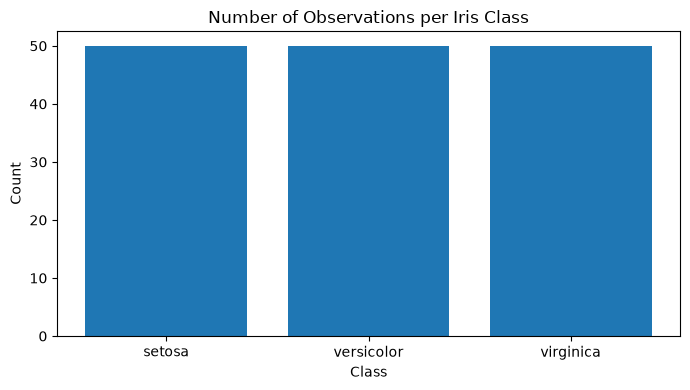

In [12]:
class_counts = y.value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(iris.target_names, class_counts.values)
plt.title("Number of Observations per Iris Class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Split data into training and testing sets while preserving class proportions

This cell performs the following step in the multiclass ANN experiment.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


### Standardize features using training-set statistics

This cell performs the following step in the multiclass ANN experiment.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)


### Inspect the standardized training features

This cell performs the following step in the multiclass ANN experiment.

In [15]:
pd.DataFrame(X_train_scaled, columns=X.columns).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-1.721568,-0.332101,-1.345722,-1.323276
1,-1.124492,-1.227655,0.414505,0.651763
2,1.144395,-0.555990,0.584850,0.256755
3,-1.124492,0.115676,-1.288941,-1.454945
4,-0.408002,-1.227655,0.130598,0.125086


### Define a feed-forward multilayer perceptron for multiclass classification

This cell performs the following step in the multiclass ANN experiment.

In [16]:
ann_model = MLPClassifier(
    hidden_layer_sizes=(10, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)
print(ann_model)

MLPClassifier(hidden_layer_sizes=(10, 8), learning_rate_init=0.01,
              max_iter=2000, random_state=42)


### Train the neural network using the training data

This cell performs the following step in the multiclass ANN experiment.

In [17]:
ann_model.fit(X_train_scaled, y_train)
print("Training completed.")
print("Iterations used:", ann_model.n_iter_)

Training completed.
Iterations used: 390


### Inspect predicted class probabilities for test observations

This cell performs the following step in the multiclass ANN experiment.

In [18]:
probabilities = ann_model.predict_proba(X_test_scaled)
predictions = ann_model.predict(X_test_scaled)
print("Classes:", ann_model.classes_)
print("Probabilities for first five test samples:")
print(np.round(probabilities[:5], 3))

Classes: [0 1 2]
Probabilities for first five test samples:
[[1.    0.    0.   ]
 [0.    0.101 0.899]
 [0.    1.    0.   ]
 [0.    1.    0.   ]
 [1.    0.    0.   ]]


### Compare actual and predicted class labels

This cell performs the following step in the multiclass ANN experiment.

In [19]:
comparison = pd.DataFrame({
    "Actual class": y_test.to_numpy(),
    "Predicted class": predictions
})
comparison["Actual species"] = comparison["Actual class"].map(dict(enumerate(iris.target_names)))
comparison["Predicted species"] = comparison["Predicted class"].map(dict(enumerate(iris.target_names)))
comparison.head(10)

,Actual class,Predicted class,Actual species,Predicted species
0,0,0,setosa,setosa
1,2,2,virginica,virginica
2,1,1,versicolor,versicolor
3,1,1,versicolor,versicolor
4,0,0,setosa,setosa
5,1,1,versicolor,versicolor
6,0,0,setosa,setosa
7,0,0,setosa,setosa
8,2,2,virginica,virginica
9,1,1,versicolor,versicolor


### Calculate the overall classification accuracy

This cell performs the following step in the multiclass ANN experiment.

In [20]:
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Accuracy: 0.9667 (96.67%)


### Calculate macro-averaged precision, recall, and F1-score

This cell performs the following step in the multiclass ANN experiment.

In [21]:
precision = precision_score(y_test, predictions, average="macro", zero_division=0)
recall = recall_score(y_test, predictions, average="macro", zero_division=0)
f1 = f1_score(y_test, predictions, average="macro", zero_division=0)
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1-score:  {f1:.4f}")

Macro Precision: 0.9697
Macro Recall:    0.9667
Macro F1-score:  0.9666


### Display detailed metrics for each class

This cell performs the following step in the multiclass ANN experiment.

In [22]:
print(classification_report(
    y_test, predictions, target_names=iris.target_names, zero_division=0
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### Create a confusion matrix

This cell performs the following step in the multiclass ANN experiment.

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


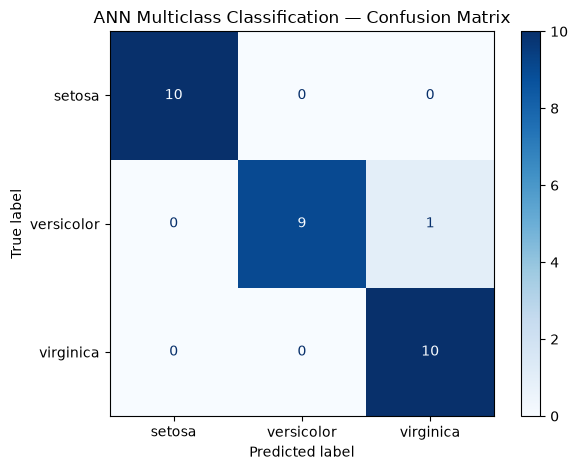

In [23]:
cm = confusion_matrix(y_test, predictions)
print(cm)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("ANN Multiclass Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

### Plot the training loss curve

This cell performs the following step in the multiclass ANN experiment.

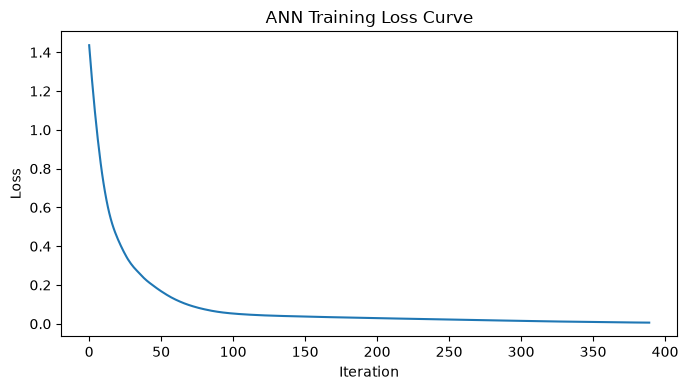

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(ann_model.loss_curve_)
plt.title("ANN Training Loss Curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.tight_layout()
plt.show()

### Predict the species of one new flower example

This cell performs the following step in the multiclass ANN experiment.

In [25]:
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)
new_flower_scaled = scaler.transform(new_flower)
new_prediction = ann_model.predict(new_flower_scaled)[0]
new_probabilities = ann_model.predict_proba(new_flower_scaled)[0]

print("Predicted species:", iris.target_names[new_prediction])
print("Class probabilities:")
for class_name, probability in zip(iris.target_names, new_probabilities):
    print(f"{class_name}: {probability:.4f}")

Predicted species: setosa
Class probabilities:
setosa: 1.0000
versicolor: 0.0000
virginica: 0.0000


### Summarize the model performance and experiment details

This cell performs the following step in the multiclass ANN experiment.

In [26]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"],
    "Score": [accuracy, precision, recall, f1]
})
display(results)
print("Input features:", list(X.columns))
print("Number of classes:", len(iris.target_names))
print("Hidden-layer sizes:", ann_model.hidden_layer_sizes)

,Metric,Score
0,Accuracy,0.966667
1,Macro Precision,0.969697
2,Macro Recall,0.966667
3,Macro F1-score,0.966583


Input features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Number of classes: 3
Hidden-layer sizes: (10, 8)


## Conclusion

In this experiment, a feed-forward Artificial Neural Network was trained to classify Iris observations into three species using four predictor variables. The features were standardized, and the data was split into training and testing sets. The model used ReLU activation in hidden layers and Softmax output probabilities for multiclass prediction. Performance was evaluated using accuracy, macro-averaged precision, recall, F1-score, and a confusion matrix. The experiment demonstrates how neural networks learn patterns from labeled data and how a separate test set can evaluate classification performance.

